# 05b Random forest on the Jeremy's starter pipeline

**Question (from a classmate):** what does our random forest score with the exact setup of the Jeremy's starter notebook?

Same as the starter notebook: dropped columns, `Frostbumps` target (muu 1 or 2), 40-row panels labelled by their last row, train = m800–m802 + m793–m795, test = m792, Kaittiaisentie as tester data. Only change: a random forest instead of the sktime model (panels flattened, because an RF needs 2D input).

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

In [2]:
# Switch for a second run later: True = also remove the position/time columns.
drop_position = False

files = sorted(Path("data_clean").glob("*.csv"))

train_dfs = []
test_dfs = []
kaitt_dfs = []

for f in files:
    df = pd.read_csv(f)
    df = df.drop(columns=["Unnamed: 0"], errors="ignore")

    # The prof's target: Frostbumps = 1 when muu is 1 or 2
    df["Frostbumps"] = df["muu"].isin([1, 2]).astype(int)

    # The prof's dropped columns (+ Speed_kmh, which only exists in our cleaned files)
    df = df.drop(columns=["posneg", "muu", "vaikeus", "Num", "East(m)", "North(m)",
                          "RBCSV_60(cf)", "Yaw(deg)", "Speed_kmh"], errors="ignore")

    if drop_position:
        df = df.drop(columns=["Timer(ms)", "Loc(m)"], errors="ignore")

    # The prof's split
    if "m792" in f.name:
        test_dfs.append(df)
    elif "Kaittiaisentie" in f.name:
        kaitt_dfs.append(df)
    else:
        train_dfs.append(df)

print("train drives:", len(train_dfs), " test drives:", len(test_dfs), " tester drives:", len(kaitt_dfs))
print("columns:", train_dfs[0].columns.tolist())

train drives: 6  test drives: 1  tester drives: 1
columns: ['Timer(ms)', 'Loc(m)', 'Speed (m/s)', 'CElev(m)', 'Roll(deg)', 'Pitch(deg)', 'AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'RBCSV_80(cf)', 'Frostbumps']


In [3]:
'''
Returns two pandas 3D panels, split as X y which are time series compliant
data structures used for machine learning models. The time step is determined
by the `sequence length`. I created this for `sktime` and `keras` but it works
for lots of other time series modules too.

dfs             = list of pandas dataframes; these are the dataframes to be converted.
sequence_length = int; time-step, determines the temporal step in rows.
target_column   = string; the name of the target column
channels_first  = boolean; default is (samples,features,timesteps), otherwise
                  it is (samples, timesteps, features)
'''
def make_panels(dfs, sequence_length, target_column, channels_first=True):

    X_panels = {}
    y_panels = {}

    for i, df in enumerate(dfs):

        X = df.drop(target_column, axis=1).to_numpy()
        y = df[target_column].to_numpy()

        n_sequences = len(X) // sequence_length

        X = X[:n_sequences * sequence_length]
        y = y[:n_sequences * sequence_length]

        X_panel = X.reshape(n_sequences,sequence_length,X.shape[1])

        # This portion changes the shape of the model depending on
        # your needs. sktime uses `True`, neural networks uses `False`
        if channels_first:
            X_panel = X_panel.transpose(0, 2, 1)
            
        y_panel = y.reshape(n_sequences,sequence_length)[:, -1]

        X_panels[i] = X_panel
        y_panels[i] = y_panel

    return X_panels, y_panels


'''
Combines lists of pandas panels to a singular X y concatenated
list of values, necessary before inserting it to any ml
models.

X_panels   = list of pandas sequential panels: Features. 
y_panels   = list of pandas sequential panels: For the target variable. 
'''
def combine_panels(X_panels, y_panels):

    X = np.concatenate(
        list(X_panels.values()),
        axis=0
    )

    y = np.concatenate(
        list(y_panels.values()),
        axis=0
    )

    return X, y

In [4]:
sequence_length = 40

X_train_panels, y_train_panels = make_panels(train_dfs, sequence_length, "Frostbumps", channels_first=True)
X_test_panels, y_test_panels = make_panels(test_dfs, sequence_length, "Frostbumps", channels_first=True)

X_train, y_train = combine_panels(X_train_panels, y_train_panels)
X_test, y_test = combine_panels(X_test_panels, y_test_panels)

# An RF needs a flat table: every panel (features x 40 rows) becomes one long row.
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("panels:", X_train.shape, "-> flat:", X_train_flat.shape)
print("test:  ", X_test.shape, "-> flat:", X_test_flat.shape)

panels: (7046, 13, 40) -> flat: (7046, 520)
test:   (160, 13, 40) -> flat: (160, 520)


In [5]:
model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
model.fit(X_train_flat, y_train)

y_prob = model.predict_proba(X_test_flat)[:, 1]
y_pred = model.predict(X_test_flat)

print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob), 2))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 2))
print("Bump share in test:", round(y_test.mean(), 2))
print(classification_report(y_test, y_pred, zero_division=0))

ROC-AUC:  0.82
Accuracy: 0.57
Bump share in test: 0.56
              precision    recall  f1-score   support

           0       0.51      0.93      0.66        70
           1       0.84      0.30      0.44        90

    accuracy                           0.57       160
   macro avg       0.68      0.61      0.55       160
weighted avg       0.70      0.57      0.54       160



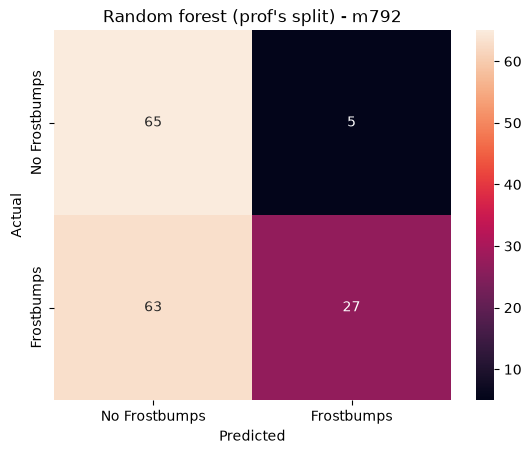

In [6]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["No Frostbumps", "Frostbumps"],
            yticklabels=["No Frostbumps", "Frostbumps"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random forest (prof's split) - m792")
plt.show()

In [7]:
X_k_panels, y_k_panels = make_panels(kaitt_dfs, sequence_length, "Frostbumps", channels_first=True)
X_k, y_k = combine_panels(X_k_panels, y_k_panels)
y_k_pred = model.predict(X_k.reshape(len(X_k), -1))

print("Kaittiaisentie accuracy:", round(accuracy_score(y_k, y_k_pred), 2))
print("Bump share:", round(y_k.mean(), 2))
print(classification_report(y_k, y_k_pred, zero_division=0))

Kaittiaisentie accuracy: 0.95
Bump share: 0.05
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      2578
           1       0.00      0.00      0.00       133

    accuracy                           0.95      2711
   macro avg       0.48      0.50      0.49      2711
weighted avg       0.90      0.95      0.93      2711



## Our pipeline on the Jeremy's split

Same split as the Jeremy's starter notebook (train m800–m802 + m793–m795, test m792, Kaittiaisentie as tester), but with our 5 m windows and speed-corrected features. Printed in the same format as the Jeremy's notebook, for comparison with 05b.

In [9]:
import pandas as pd

# Load the windows (as at the top of 05)
windows = pd.read_csv("data_features/windows_5m.csv")
windows = windows[windows["label"] != "left out"].copy()
windows["is_bump"] = (windows["label"] == "bump").astype(int)

# Relative (speed-corrected) features (as in 05)
std_features = ["GyrY_std", "AccZ_std", "GyrX_std", "GyrZ_std", "AccY_std", "AccX_std", "Pitch_std"]
for col in std_features:
    calm_level = windows.groupby("drive")[col].transform(lambda s: s.quantile(0.25))
    windows[col + "_rel"] = windows[col] / calm_level
rel_features = [col + "_rel" for col in std_features]

print(windows.shape)

(2728, 53)


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# The prof's split, on our windows
is_test = windows["drive"].str.contains("m792")
is_train = (~is_test) & (windows["road"] != "Kaittiaisentie")
is_kaitt = windows["road"] == "Kaittiaisentie"

train = windows[is_train]
test = windows[is_test]
kaitt = windows[is_kaitt]

# Same RF and features as always
model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
model.fit(train[rel_features], train["is_bump"])

# ---- m792 (the prof's test drive) ----
y_pred = model.predict(test[rel_features])
y_prob = model.predict_proba(test[rel_features])[:, 1]

print("TEST: m792")
print("ROC-AUC: ", round(roc_auc_score(test["is_bump"], y_prob), 2))
print("Accuracy:", round(accuracy_score(test["is_bump"], y_pred), 2))
print("Bump share in test:", round(test["is_bump"].mean(), 2))
print(classification_report(test["is_bump"], y_pred, zero_division=0))

# ---- Kaittiaisentie (the prof's tester road) ----
y_k_pred = model.predict(kaitt[rel_features])

print("KAITTIAISENTIE")
print("Accuracy:", round(accuracy_score(kaitt["is_bump"], y_k_pred), 2))
print("Bump share:", round(kaitt["is_bump"].mean(), 2))
print(classification_report(kaitt["is_bump"], y_k_pred, zero_division=0))

TEST: m792
ROC-AUC:  0.71
Accuracy: 0.66
Bump share in test: 0.62
              precision    recall  f1-score   support

           0       0.53      1.00      0.69        21
           1       1.00      0.46      0.63        35

    accuracy                           0.66        56
   macro avg       0.76      0.73      0.66        56
weighted avg       0.82      0.66      0.65        56

KAITTIAISENTIE
Accuracy: 0.88
Bump share: 0.05
              precision    recall  f1-score   support

           0       0.99      0.89      0.94       584
           1       0.27      0.80      0.40        30

    accuracy                           0.88       614
   macro avg       0.63      0.84      0.67       614
weighted avg       0.95      0.88      0.91       614



### Result: same split, same random forest, different pipeline

| | Prof's pipeline (exact) | Prof's pipeline, no Timer/Loc | **Our pipeline** |
|---|---|---|---|
| m792 accuracy (baseline 0.56 / 0.62) | 0.57 | 0.61 | **0.66** |
| m792 bumps found (recall) | 30% | 30% | **46%** |
| m792 bump F1 | 0.44 | 0.46 | **0.63** |
| Kaittiaisentie accuracy (baseline 0.95) | **0.95** | 0.89 | 0.88 |
| Kaittiaisentie bumps found (recall) | **0%** | 4% | **80%** |

- With the same split and the same model, our pipeline (5 m windows, speed-corrected features) finds far more bumps. The difference comes from the input, not the model.
- On Kaittiaisentie the prof's pipeline has the highest accuracy (0.95) while finding no bumps at all; ours has lower accuracy but finds 80% of them. Accuracy is misleading when bumps are rare.
- No pipeline reaches 85% accuracy on m792 (a short drive with long, flat-topped heaves).